In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

VIDEOS_CSV = ROOT / "data/video_predictions/videos.csv"
BIRDS_CSV = ROOT / "data/video_predictions/aves.csv"
OUT_DIR = ROOT / "runs/pipeline/kaggle_evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

videos = pd.read_csv(VIDEOS_CSV)
birds = pd.read_csv(BIRDS_CSV)
CLASSES = [c[2:] for c in birds.columns if c.startswith("p_")]
PROB_COLS = ["p_" + c for c in CLASSES]
metrics = {}

def species_key(name):
    parts = str(name).split("_")
    return (parts[0].lower().rstrip("s"), parts[1].lower() if len(parts) > 1 else "")

KEY_TO_CLASS = {species_key(c): c for c in CLASSES}
videos["real"] = videos["especie_real"].map(lambda n: KEY_TO_CLASS.get(species_key(n)))
videos["fora_das_classes"] = videos["real"].isna()

print(f"{len(videos)} vídeos, {len(birds)} aves, {len(CLASSES)} classes")
print("Fora das classes (excluídos da acurácia):", videos.loc[videos.fora_das_classes, "especie_real"].unique().tolist())
print(videos.groupby("real").size().rename("vídeos por espécie real").to_string())

weighted_sum = birds[PROB_COLS].mul(birds["quadros"], axis=0).groupby(birds["video"]).sum()
weighted_mean = weighted_sum.div(birds.groupby("video")["quadros"].sum(), axis=0)
weighted_mean.columns = CLASSES
ranking = np.argsort(-weighted_mean.values, axis=1)
recomputed = pd.DataFrame({
    "top1": [CLASSES[i] for i in ranking[:, 0]],
    "top2": [CLASSES[i] for i in ranking[:, 1]],
    "top1_prob": weighted_mean.values[np.arange(len(weighted_mean)), ranking[:, 0]],
    "top2_prob": weighted_mean.values[np.arange(len(weighted_mean)), ranking[:, 1]],
}, index=weighted_mean.index)
reference = videos.set_index("video").loc[recomputed.index]
print("\nConferência da média ponderada (aves.csv x videos.csv)")
print(f"vídeos conferidos: {len(recomputed)} | sem aves no aves.csv: {len(videos) - len(recomputed)}")
print(f"top1 iguais: {(recomputed.top1 == reference.top1).sum()}/{len(recomputed)} | top2 iguais: {(recomputed.top2 == reference.top2).sum()}/{len(recomputed)}")
print(f"dif. máx top1_prob: {(recomputed.top1_prob - reference.top1_prob).abs().max():.2e} | top2_prob: {(recomputed.top2_prob - reference.top2_prob).abs().max():.2e}")
metrics["conferencia"] = {
    "videos_conferidos": len(recomputed),
    "top1_iguais": int((recomputed.top1 == reference.top1).sum()),
    "top2_iguais": int((recomputed.top2 == reference.top2).sum()),
    "dif_max_top1_prob": float((recomputed.top1_prob - reference.top1_prob).abs().max()),
}

85 vídeos, 204 aves, 10 classes
Fora das classes (excluídos da acurácia): []
real
Allens_Hummingbird           18
Black-chinned_Hummingbird    17
Broad-billed_Hummingbird      2
Calliope_Hummingbird          7
Costas_Hummingbird           18
Green_Violetear               3
Rufous_Hummingbird           20

Conferência da média ponderada (aves.csv x videos.csv)
vídeos conferidos: 83 | sem aves no aves.csv: 2
top1 iguais: 83/83 | top2 iguais: 83/83
dif. máx top1_prob: 1.11e-16 | top2_prob: 8.33e-17


Vídeos avaliados: 85 (sem predição, contados como erro: 2)
Acurácia top-1: 0.6118 (52/85)
Acurácia top-2: 0.8824 (75/85)


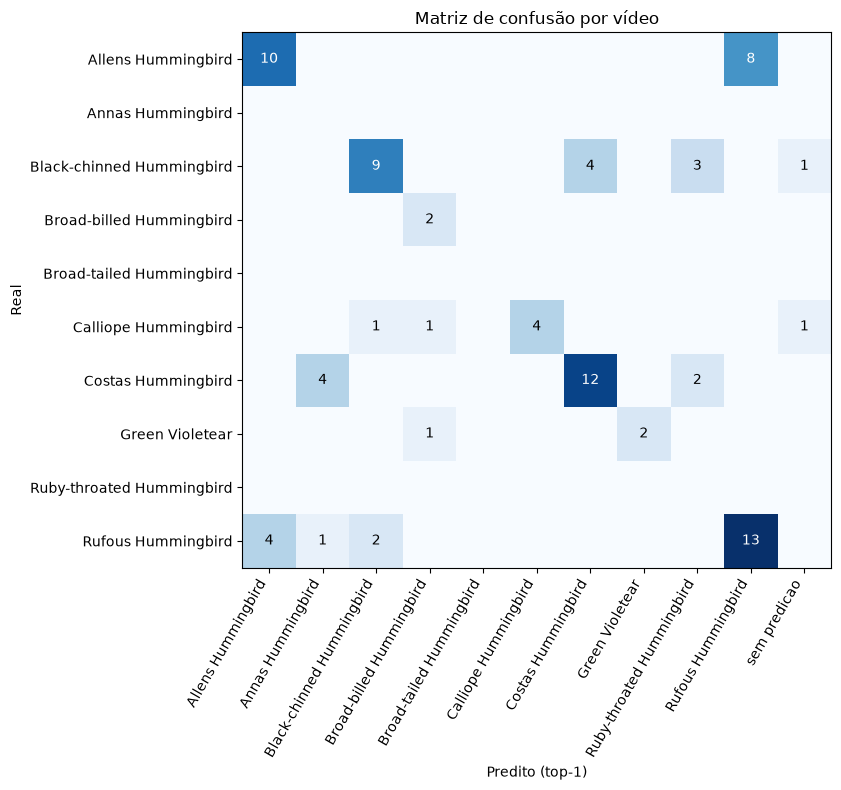

                           Allens_Hummingbird  Annas_Hummingbird  Black-chinned_Hummingbird  Broad-billed_Hummingbird  Calliope_Hummingbird  Costas_Hummingbird  Green_Violetear  Ruby-throated_Hummingbird  Rufous_Hummingbird  sem_predicao
Allens_Hummingbird                         10                  0                          0                         0                     0                   0                0                          0                   8             0
Black-chinned_Hummingbird                   0                  0                          9                         0                     0                   4                0                          3                   0             1
Broad-billed_Hummingbird                    0                  0                          0                         2                     0                   0                0                          0                   0             0
Calliope_Hummingbird                        0   

In [2]:
evaluated = videos[~videos.fora_das_classes].copy()
evaluated["top1_ok"] = evaluated["top1"] == evaluated["real"]
evaluated["top2_ok"] = evaluated["top1_ok"] | (evaluated["top2"] == evaluated["real"])
evaluated["sem_predicao"] = evaluated["top1"].isna()
y_pred = evaluated["top1"].fillna("sem_predicao")

n_videos = len(evaluated)
metrics["acuracia"] = {
    "videos_avaliados": n_videos,
    "sem_predicao": int(evaluated.sem_predicao.sum()),
    "top1": float(evaluated.top1_ok.mean()),
    "top2": float(evaluated.top2_ok.mean()),
}
print(f"Vídeos avaliados: {n_videos} (sem predição, contados como erro: {int(evaluated.sem_predicao.sum())})")
print(f"Acurácia top-1: {evaluated.top1_ok.mean():.4f} ({evaluated.top1_ok.sum()}/{n_videos})")
print(f"Acurácia top-2: {evaluated.top2_ok.mean():.4f} ({evaluated.top2_ok.sum()}/{n_videos})")

pred_labels = CLASSES + ["sem_predicao"]
cm = confusion_matrix(evaluated["real"], y_pred, labels=pred_labels)[:len(CLASSES)]
cm_df = pd.DataFrame(cm, index=CLASSES, columns=pred_labels)
cm_df.to_csv(OUT_DIR / "matriz_confusao.csv")

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(pred_labels)), [c.replace("_", " ") for c in pred_labels], rotation=60, ha="right")
ax.set_yticks(range(len(CLASSES)), [c.replace("_", " ") for c in CLASSES])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predito (top-1)")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusão por vídeo")
fig.tight_layout()
fig.savefig(OUT_DIR / "matriz_confusao.png", dpi=150)
plt.show()
print(cm_df.loc[:, (cm_df != 0).any()].loc[(cm_df != 0).any(axis=1)].to_string())

In [3]:
precision, recall, f1, support = precision_recall_fscore_support(
    evaluated["real"], y_pred, labels=CLASSES, zero_division=0)
per_class = pd.DataFrame({"precisao": precision, "recall": recall, "f1": f1, "suporte": support,
                          "predicoes": [(y_pred == c).sum() for c in CLASSES]}, index=CLASSES)
per_class.to_csv(OUT_DIR / "metricas_por_classe.csv")
with_support = per_class[per_class.suporte > 0]
macro = with_support[["precisao", "recall", "f1"]].mean()
print(per_class.round(4).to_string())
print(f"\nMédia macro (classes com suporte > 0): precisão {macro.precisao:.4f} | recall {macro.recall:.4f} | F1 {macro.f1:.4f}")
metrics["por_classe"] = per_class.round(4).to_dict("index")
metrics["macro"] = macro.round(4).to_dict()

with_prob = evaluated[~evaluated.sem_predicao].copy()
with_prob["faixa"] = pd.cut(with_prob["top1_prob"], bins=[0, 0.5, 0.7, 0.9, 1.0],
                            labels=["ate 0.5", "0.5 a 0.7", "0.7 a 0.9", "acima de 0.9"],
                            include_lowest=True)
by_confidence = with_prob.groupby("faixa", observed=False).agg(
    videos=("video", "size"), acc_top1=("top1_ok", "mean"), acc_top2=("top2_ok", "mean")).round(4)
by_confidence.index = by_confidence.index.astype(str)
by_confidence.to_csv(OUT_DIR / "acerto_por_confianca.csv")
print("\nAcerto por faixa de confiança (top1_prob do vídeo)")
print(by_confidence.to_string())
metrics["faixas_confianca"] = by_confidence.to_dict("index")

                           precisao  recall      f1  suporte  predicoes
Allens_Hummingbird           0.7143  0.5556  0.6250       18         14
Annas_Hummingbird            0.0000  0.0000  0.0000        0          5
Black-chinned_Hummingbird    0.7500  0.5294  0.6207       17         12
Broad-billed_Hummingbird     0.5000  1.0000  0.6667        2          4
Broad-tailed_Hummingbird     0.0000  0.0000  0.0000        0          0
Calliope_Hummingbird         1.0000  0.5714  0.7273        7          4
Costas_Hummingbird           0.7500  0.6667  0.7059       18         16
Green_Violetear              1.0000  0.6667  0.8000        3          2
Ruby-throated_Hummingbird    0.0000  0.0000  0.0000        0          5
Rufous_Hummingbird           0.6190  0.6500  0.6341       20         21

Média macro (classes com suporte > 0): precisão 0.7619 | recall 0.6628 | F1 0.6828

Acerto por faixa de confiança (top1_prob do vídeo)
              videos  acc_top1  acc_top2
faixa                          

In [4]:
track_sizes = birds.groupby("video")["quadros"].agg(total="sum", principal="max")
fragmentation = (track_sizes.principal / track_sizes.total).rename("fracao_track_principal")
videos = videos.merge(fragmentation, left_on="video", right_index=True, how="left")
evaluated = evaluated.merge(fragmentation, left_on="video", right_index=True, how="left")

rate = videos["taxa_deteccao"]
detection = {
    "taxa_media": rate.mean(), "taxa_mediana": rate.median(), "taxa_min": rate.min(),
    "taxa_global": videos.quadros_com_deteccao.sum() / videos.quadros.sum(),
    "videos_sem_nenhuma_deteccao": int((videos.quadros_com_deteccao == 0).sum()),
    "videos_taxa_abaixo_50pct": int((rate < 0.5).sum()),
}
print("Taxa de detecção")
for k, v in detection.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

n_birds = videos["n_aves"]
frag_stats = {
    "n_aves_media": n_birds.mean(), "n_aves_mediana": n_birds.median(), "n_aves_max": int(n_birds.max()),
    "videos_com_n_aves_1": int((n_birds == 1).sum()), "pct_videos_n_aves_1": (n_birds == 1).mean(),
    "tracks_excedentes_total": int((n_birds - 1).clip(lower=0).sum()),
    "fracao_track_principal_media": videos.fracao_track_principal.mean(),
    "fracao_track_principal_mediana": videos.fracao_track_principal.median(),
}
print("\nFragmentação (cada vídeo tem 1 ave real)")
for k, v in frag_stats.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")
print("\nVídeos por n_aves:")
print(n_birds.value_counts().sort_index().rename("vídeos").to_string())

evaluated["grupo_n_aves"] = pd.cut(evaluated["n_aves"], bins=[-1, 0, 1, np.inf], labels=["0", "1", ">1"])
by_n_birds = evaluated.groupby("grupo_n_aves", observed=True).agg(
    videos=("video", "size"), acc_top1=("top1_ok", "mean"), acc_top2=("top2_ok", "mean"),
    fracao_track_principal=("fracao_track_principal", "mean")).round(4)
by_n_birds.to_csv(OUT_DIR / "acerto_por_n_aves.csv")
print("\nAcerto por grupo de n_aves")
print(by_n_birds.to_string())

fps_col = videos["fps"]
speed = {"fps_media": fps_col.mean(), "fps_mediana": fps_col.median(), "fps_min": fps_col.min(), "fps_max": fps_col.max(),
         "fps_global": videos.quadros.sum() / videos.tempo_s.sum(), "tempo_total_s": videos.tempo_s.sum()}
print("\nVelocidade")
for k, v in speed.items():
    print(f"  {k}: {v:.2f}")

metrics["deteccao"] = detection
metrics["fragmentacao"] = frag_stats
metrics["n_aves_dist"] = {str(k): int(v) for k, v in n_birds.value_counts().sort_index().items()}
metrics["acerto_por_n_aves"] = by_n_birds.to_dict("index")
metrics["velocidade"] = speed

Taxa de detecção
  taxa_media: 0.8424
  taxa_mediana: 0.9631
  taxa_min: 0.0000
  taxa_global: 0.8544
  videos_sem_nenhuma_deteccao: 1
  videos_taxa_abaixo_50pct: 10

Fragmentação (cada vídeo tem 1 ave real)
  n_aves_media: 2.4000
  n_aves_mediana: 1.0000
  n_aves_max: 22
  videos_com_n_aves_1: 58
  pct_videos_n_aves_1: 0.6824
  tracks_excedentes_total: 121
  fracao_track_principal_media: 0.8711
  fracao_track_principal_mediana: 1.0000

Vídeos por n_aves:
n_aves
0      2
1     58
2      9
3      2
4      1
5      2
6      2
7      1
8      3
9      1
10     2
14     1
22     1

Acerto por grupo de n_aves
              videos  acc_top1  acc_top2  fracao_track_principal
grupo_n_aves                                                    
0                  2    0.0000    0.0000                     NaN
1                 58    0.6207    0.9138                  1.0000
>1                25    0.6400    0.8800                  0.5722

Velocidade
  fps_media: 26.46
  fps_mediana: 23.97
  fps_min: 

In [5]:
output_columns = ["video", "origem", "especie_real", "real", "top1", "top1_prob", "top2", "top2_prob",
                  "top1_ok", "top2_ok", "n_aves", "fracao_track_principal", "taxa_deteccao", "fps"]
evaluated[output_columns].to_csv(OUT_DIR / "avaliacao_por_video.csv", index=False)
with open(OUT_DIR / "metricas.json", "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(sorted(p.name for p in OUT_DIR.iterdir()))

['acerto_por_confianca.csv', 'acerto_por_n_aves.csv', 'avaliacao_por_video.csv', 'matriz_confusao.csv', 'matriz_confusao.png', 'metricas.json', 'metricas_por_classe.csv']
